QUANTUM METROLOGY ENGINE — QFI ANALYSIS
State            t         p      Ideal QFI      Noisy QFI
------------------------------------------------------------------------------------
[CHECK] Single-qubit benchmark at p = 0.25
        Numerical QFI : 0.75000000
        Theory (1 - p): 0.75000000
        Residual      : 5.551e-16
------------------------------------------------------------------------------------
Product      0.000   0.00000       3.000000       3.000000
GHZ          0.000   0.00000       9.000000       9.000000
Product      0.150   0.01784       3.000000       2.946483
GHZ          0.150   0.01784       8.914014       8.672599
Product      0.300   0.03536       3.000000       2.893921
GHZ          0.300   0.03536       8.660985       8.187613
Product      0.450   0.05257       3.000000       2.842296
GHZ          0.450   0.05257       8.255417       7.569258
Product      0.600   0.06947       3.000000       2.791593
GHZ          0.600   0.06947       7.720560       6.8

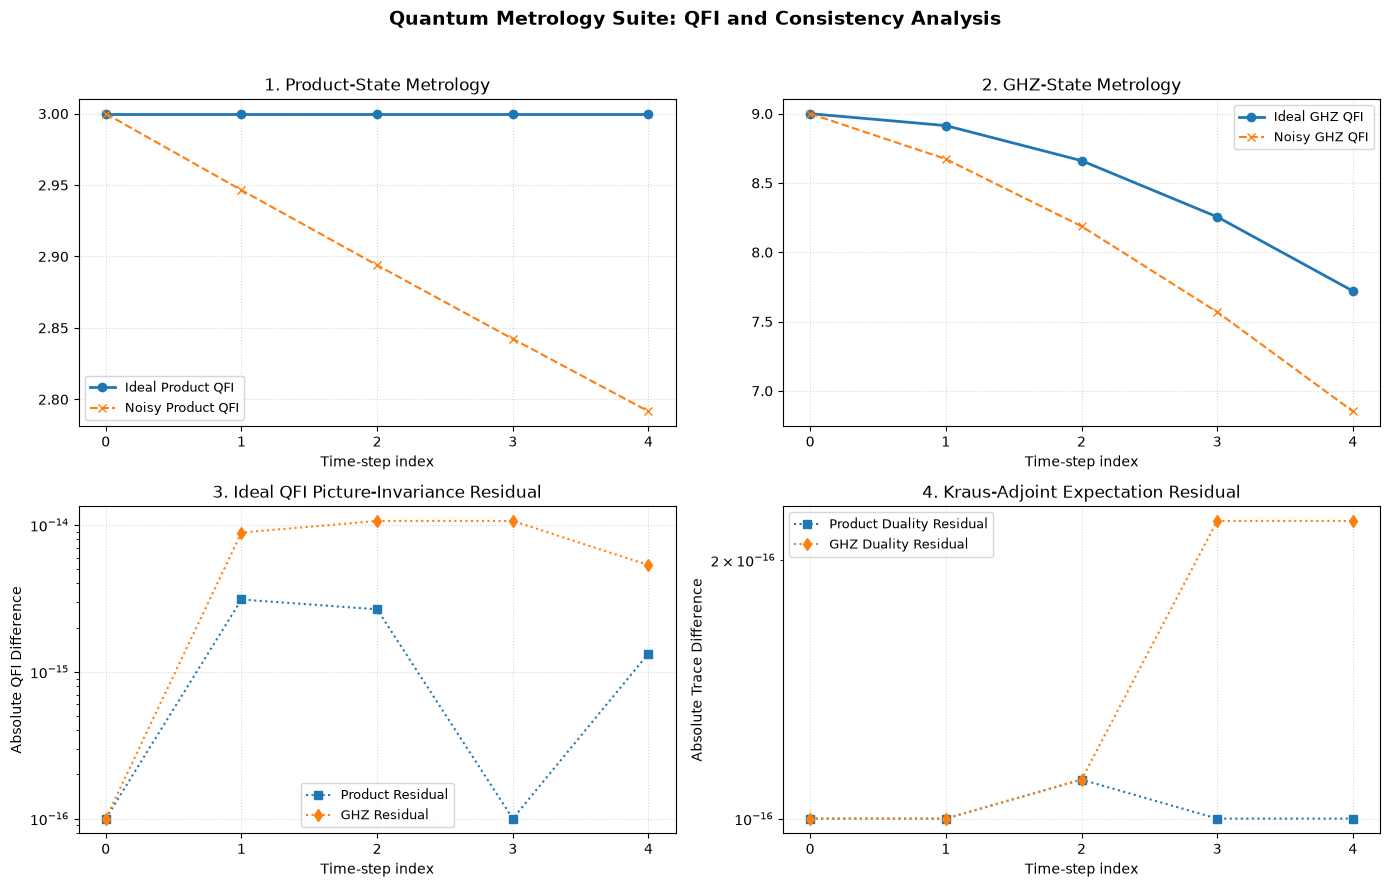

In [2]:
# ============================================================================
# Quantum Metrology Engine
# ----------------------------------------------------------------------------
# Numerical Quantum Fisher Information (QFI) for N-qubit probe states under
# unitary evolution, phase encoding, and independent amplitude damping.
#
# Pipeline:  rho_0 -> U(t) -> U_theta = exp(-i*theta*G) -> amplitude damping
#   H    = 0.4 * sum_i X_i         evolution Hamiltonian
#   G    = 1/2 * sum_i Z_i         phase-encoding generator
#   p(t) = 1 - exp(-gamma * t)     damping probability
#
# Conventions: hbar = 1 (dimensionless units). The parameter derivative is
# taken at theta = 0, i.e. on the state after the unitary evolution U(t).
#
# Consistency checks performed:
#   1. Single-qubit benchmark with the analytic result F_Q = 1 - p.
#   2. Schrodinger- vs Heisenberg-picture QFI for the ideal (noise-free) case.
#   3. Kraus-adjoint duality: Tr[A E(rho)] = Tr[E*(A) rho].
# ============================================================================

import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# ============================================================================
# 1. Physical-State and Numerical Validation
# ============================================================================

def verify_physical_state(rho, atol=1e-8):
    """Verify that rho is a mathematically valid density matrix."""
    rho = np.asarray(rho, dtype=complex)

    if rho.ndim != 2 or rho.shape[0] != rho.shape[1]:
        raise ValueError("Density matrix must be square.")

    if not np.all(np.isfinite(rho)):
        raise ValueError("Density matrix contains non-finite values.")

    if not np.allclose(rho, rho.conj().T, atol=atol):
        raise ValueError("Density matrix is not Hermitian.")

    if not np.isclose(np.trace(rho).real, 1.0, atol=atol):
        raise ValueError("Density matrix must have trace 1.")

    eigenvalues = np.linalg.eigvalsh((rho + rho.conj().T) / 2)
    if np.min(eigenvalues) < -atol:
        raise ValueError("Density matrix is not positive semidefinite.")

    return True

def verify_density_derivative(d_rho, dim, atol=1e-8):
    """Verify basic structural requirements for a density matrix derivative."""
    d_rho = np.asarray(d_rho, dtype=complex)

    if d_rho.shape != (dim, dim):
        raise ValueError("d_rho has the wrong dimensions.")

    if not np.all(np.isfinite(d_rho)):
        raise ValueError("d_rho contains non-finite values.")

    if not np.allclose(d_rho, d_rho.conj().T, atol=atol):
        raise ValueError("d_rho must be Hermitian.")

    if not np.isclose(np.trace(d_rho).real, 0.0, atol=atol):
        raise ValueError("d_rho must have trace zero.")

    return True

# ============================================================================
# 2. Quantum Fisher Information Engine (SLD Basis)
# ============================================================================

def compute_generalized_mixed_qfi(rho, d_rho_matrix, tol=1e-10):
    """
    Calculate the Symmetric Logarithmic Derivative (SLD) Quantum Fisher Information.

    In the eigenbasis of rho = sum_i p_i |i><i|, the QFI is
        F_Q = sum_{i,j} 2 * |<i| d_rho |j>|^2 / (p_i + p_j).
    Terms with p_i + p_j <= tol (both eigenvalues numerically zero) are omitted
    to avoid division by zero. This is the standard convention and assumes that
    d_rho has no components inside the kernel of rho.
    """
    rho = np.asarray(rho, dtype=complex)
    d_rho_matrix = np.asarray(d_rho_matrix, dtype=complex)

    verify_physical_state(rho)
    verify_density_derivative(d_rho_matrix, rho.shape[0])

    eigenvalues, eigenvectors = np.linalg.eigh(rho)
    d_rho_eigenbasis = eigenvectors.conj().T @ d_rho_matrix @ eigenvectors

    qfi = 0.0
    for i, pi in enumerate(eigenvalues):
        for j, pj in enumerate(eigenvalues):
            denominator = pi + pj
            if denominator > tol:
                qfi += 2.0 * abs(d_rho_eigenbasis[i, j]) ** 2 / denominator

    qfi = float(np.real(qfi))
    if qfi < -1e-8:
        raise ArithmeticError("Computed QFI is unexpectedly negative.")

    return max(qfi, 0.0)
# ============================================================================
# 3. Tensor Products and Kraus Channel Maps
# ============================================================================

def tensor_product_operators(operators):
    """Calculate the Kronecker product of a non-empty sequence of operators."""
    if len(operators) == 0:
        raise ValueError("At least one operator is required.")

    result = np.asarray(operators[0], dtype=complex)
    for operator in operators[1:]:
        result = np.kron(result, np.asarray(operator, dtype=complex))

    return result

def apply_kraus_channel(rho, kraus_ops):
    """Schrödinger Picture: Apply E(rho) = sum_k E_k * rho * E_k^dagger."""
    rho = np.asarray(rho, dtype=complex)
    result = np.zeros_like(rho, dtype=complex)

    for operator in kraus_ops:
        result += operator @ rho @ operator.conj().T

    # Symmetrize to remove tiny anti-Hermitian round-off error.
    return (result + result.conj().T) / 2

def apply_dual_kraus_map(operator, kraus_ops):
    """Heisenberg Picture Adjoint Map: E*(A) = sum_k E_k^dagger * A * E_k."""
    operator = np.asarray(operator, dtype=complex)
    result = np.zeros_like(operator, dtype=complex)

    for kraus_operator in kraus_ops:
        result += kraus_operator.conj().T @ operator @ kraus_operator

    # Symmetrize to remove tiny anti-Hermitian round-off error.
    return (result + result.conj().T) / 2

def verify_kraus_completeness(kraus_ops, atol=1e-8):
    """Verify the trace-preserving condition: sum_k E_k^dagger * E_k = I."""
    if not kraus_ops:
        raise ValueError("The Kraus-operator list cannot be empty.")

    dim = kraus_ops[0].shape[0]
    identity = np.eye(dim, dtype=complex)
    total = np.zeros((dim, dim), dtype=complex)

    for operator in kraus_ops:
        if operator.shape != (dim, dim):
            raise ValueError("All Kraus operators must have equal dimensions.")
        total += operator.conj().T @ operator

    if not np.allclose(total, identity, atol=atol):
        raise ValueError("Kraus completeness condition failed.")

    return True

# ============================================================================
# 4. Probe States and Physical System Matrices
# ============================================================================

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

ZERO = np.array([[1], [0]], dtype=complex)
ONE = np.array([[0], [1]], dtype=complex)
PLUS = (ZERO + ONE) / np.sqrt(2)  # |+> = (|0> + |1>) / sqrt(2)

def build_initial_probe_density(n_qubits, entangled=False):
    """Construct an initial product state |+>^N or an N-qubit GHZ state density matrix."""
    if not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits must be a positive integer.")

    if entangled:
        zero_state = ZERO
        one_state = ONE
        for _ in range(n_qubits - 1):
            zero_state = np.kron(zero_state, ZERO)
            one_state = np.kron(one_state, ONE)
        state = (zero_state + one_state) / np.sqrt(2)
    else:
        state = PLUS
        for _ in range(n_qubits - 1):
            state = np.kron(state, PLUS)

    rho = state @ state.conj().T
    verify_physical_state(rho)
    return rho

def build_amplitude_damping_kraus(n_qubits, p):
    """Build global Kraus operators for independent amplitude damping channels on N qubits."""
    if not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits must be a positive integer.")
    if not np.isfinite(p) or not 0.0 <= p <= 1.0:
        raise ValueError("Damping probability p must be between 0 and 1.")

    e0 = np.array([[1, 0], [0, np.sqrt(1.0 - p)]], dtype=complex)
    e1 = np.array([[0, np.sqrt(p)], [0, 0]], dtype=complex)

    single_qubit_ops = [e0, e1]
    global_ops = []

    # One global Kraus operator per choice of (E0 or E1) on each qubit:
    # 2**N operators, each a 2**N x 2**N matrix. This exponential cost is
    # what limits this implementation to small N.
    for choices in itertools.product(range(2), repeat=n_qubits):
        local_ops = [single_qubit_ops[index] for index in choices]
        global_ops.append(tensor_product_operators(local_ops))

    verify_kraus_completeness(global_ops)
    return global_ops

def build_base_generator(n_qubits):
    """Construct parametric phase generator matrix G = (1/2) * sum_i Z_i."""
    terms = []
    for target in range(n_qubits):
        local_ops = [Z if qubit == target else I2 for qubit in range(n_qubits)]
        terms.append(tensor_product_operators(local_ops))
    return 0.5 * sum(terms)

def build_evolution_hamiltonian(n_qubits, coupling=0.4):
    """Construct system Hamiltonian matrix H = coupling * sum_i X_i."""
    terms = []
    for target in range(n_qubits):
        local_ops = [X if qubit == target else I2 for qubit in range(n_qubits)]
        terms.append(tensor_product_operators(local_ops))
    return coupling * sum(terms)
# ============================================================================
# 5. Independent Single-Qubit Analytical Validation
# ============================================================================

def run_single_qubit_analytical_check(p):
    """Verify N=1 qubit: Product state |+><+| -> Damping Channel -> theory QFI = 1 - p."""
    rho0 = build_initial_probe_density(1)
    generator = 0.5 * Z
    kraus_ops = build_amplitude_damping_kraus(1, p)

    # Compute the parameter derivative of the input state
    d_rho = -1j * (generator @ rho0 - rho0 @ generator)

    # The channel does not depend on theta, so d/dtheta E(rho) = E(d_rho);
    # the same channel is therefore applied to the state and its derivative.
    rho_out = apply_kraus_channel(rho0, kraus_ops)
    d_rho_out = apply_kraus_channel(d_rho, kraus_ops)

    qfi_numeric = compute_generalized_mixed_qfi(rho_out, d_rho_out)
    qfi_analytic = 1.0 - p
    return qfi_numeric, qfi_analytic

# ============================================================================
# 6. Main Metrology Experiment
# ============================================================================

def main():
    n_qubits = 3            # number of probe qubits (Hilbert-space dimension 2**n_qubits)
    time_steps = 5          # number of sampled evolution times: t = 0, dt, 2*dt, ...
    dt = 0.15               # time step (dimensionless units, hbar = 1)
    gamma_damping = 0.12    # amplitude-damping rate, used in p(t) = 1 - exp(-gamma*t)

    generator = build_base_generator(n_qubits)
    hamiltonian = build_evolution_hamiltonian(n_qubits)

    probe_states = {
        "Product": build_initial_probe_density(n_qubits, entangled=False),
        "GHZ": build_initial_probe_density(n_qubits, entangled=True),
    }

    ideal_qfi = {name: [] for name in probe_states}
    noisy_qfi = {name: [] for name in probe_states}
    ideal_picture_residuals = {name: [] for name in probe_states}
    adjoint_duality_residuals = {name: [] for name in probe_states}

    print("=" * 84)
    print("QUANTUM METROLOGY ENGINE — QFI ANALYSIS")
    print("=" * 84)
    print(f"{'State':<10} {'t':>7} {'p':>9} {'Ideal QFI':>14} {'Noisy QFI':>14}")
    print("-" * 84)

    # Independent single-qubit analytical benchmark checkpoint
    p_test = 0.25
    numerical, analytical = run_single_qubit_analytical_check(p_test)

    print(f"[CHECK] Single-qubit benchmark at p = {p_test:.2f}")
    print(f"        Numerical QFI : {numerical:.8f}")
    print(f"        Theory (1 - p): {analytical:.8f}")
    print(f"        Residual      : {abs(numerical - analytical):.3e}")
    print("-" * 84)

    for step in range(time_steps):
        t = step * dt
        p = 1.0 - np.exp(-gamma_damping * t)

        unitary = expm(-1j * hamiltonian * t)
        kraus_ops = build_amplitude_damping_kraus(n_qubits, p)

        for name, rho0 in probe_states.items():
            # --- Schrödinger Picture: Output-State QFI Pipeline ---
            rho_evolved = unitary @ rho0 @ unitary.conj().T
            rho_evolved = (rho_evolved + rho_evolved.conj().T) / 2

            # Phase encoding U_theta = exp(-i*theta*G) at theta = 0 gives
            # d_rho/dtheta = -i [G, rho_evolved].
            d_rho_ideal = -1j * (generator @ rho_evolved - rho_evolved @ generator)
            qfi_val_ideal = compute_generalized_mixed_qfi(rho_evolved, d_rho_ideal)

            # Noisy case: the damping channel acts on both the state and its
            # derivative (the channel itself does not depend on theta).
            rho_noisy = apply_kraus_channel(rho_evolved, kraus_ops)
            d_rho_noisy = apply_kraus_channel(d_rho_ideal, kraus_ops)
            qfi_val_noisy = compute_generalized_mixed_qfi(rho_noisy, d_rho_noisy)

            ideal_qfi[name].append(qfi_val_ideal)
            noisy_qfi[name].append(qfi_val_noisy)

            # --- Heisenberg Picture: Ideal Frame Invariance Track ---
            # Move U(t) onto the generator, G_H = U^dagger G U, and differentiate
            # the INITIAL state instead. For ideal (unitary) evolution this must
            # reproduce the Schrodinger-picture QFI computed above.
            generator_heisenberg = unitary.conj().T @ generator @ unitary
            d_rho_h_ideal = -1j * (generator_heisenberg @ rho0 - rho0 @ generator_heisenberg)
            qfi_val_h_ideal = compute_generalized_mixed_qfi(rho0, d_rho_h_ideal)

            ideal_picture_residuals[name].append(abs(qfi_val_ideal - qfi_val_h_ideal))

            # --- Kraus-Adjoint Duality Identity Trace Check ---
            # Duality check: Tr[G * E(rho)] must equal Tr[E*(G) * rho],
            # where E* is the adjoint (Heisenberg-picture) channel.
            lhs_trace = np.trace(generator @ rho_noisy).real
            dual_observable = apply_dual_kraus_map(generator, kraus_ops)
            rhs_trace = np.trace(dual_observable @ rho_evolved).real

            adjoint_duality_residuals[name].append(abs(lhs_trace - rhs_trace))

            print(f"{name:<10} {t:>7.3f} {p:>9.5f} {qfi_val_ideal:>14.6f} {qfi_val_noisy:>14.6f}")

    # --- Verification Summary ---
    max_ideal_residual = max(max(values) for values in ideal_picture_residuals.values())
    max_duality_residual = max(max(values) for values in adjoint_duality_residuals.values())

    print("-" * 84)
    print("CONSISTENCY CHECKS")
    print(f"Maximum ideal QFI picture residual : {max_ideal_residual:.3e}")
    print(f"Maximum Kraus duality residual      : {max_duality_residual:.3e}")

    # Pass/fail tolerance of 1e-7: far above floating-point round-off
    # (residuals here are ~1e-14 to 1e-16) and far below the QFI values.
    if abs(numerical - analytical) > 1e-7:
        print("[WARNING] Single-qubit analytical benchmark did not pass tolerance.")
    else:
        print("[OK] Single-qubit analytical benchmark passed.")

    if max_ideal_residual > 1e-7:
        print("[WARNING] Ideal-picture QFI residual is larger than expected.")
    else:
        print("[OK] Ideal-picture QFI invariance passed.")

    if max_duality_residual > 1e-7:
        print("[WARNING] Kraus-adjoint duality residual is larger than expected.")
    else:
        print("[OK] Kraus-adjoint duality check passed.")

    # --- Plotting Sequence ---
    fig, axs = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle("Quantum Metrology Suite: QFI and Consistency Analysis", fontsize=14, fontweight="bold")
    steps_range = np.arange(time_steps)  # x-axis is the step index; step k is t = k * dt

    axs[0, 0].plot(steps_range, ideal_qfi["Product"], "o-", linewidth=2, label="Ideal Product QFI")
    axs[0, 0].plot(steps_range, noisy_qfi["Product"], "x--", linewidth=1.5, label="Noisy Product QFI")
    axs[0, 0].set_title("1. Product-State Metrology")

    axs[0, 1].plot(steps_range, ideal_qfi["GHZ"], "o-", linewidth=2, label="Ideal GHZ QFI")
    axs[0, 1].plot(steps_range, noisy_qfi["GHZ"], "x--", linewidth=1.5, label="Noisy GHZ QFI")
    axs[0, 1].set_title("2. GHZ-State Metrology")

    # Residual panels use a log axis, so values are floored at 1e-16 for display:
    # a point drawn at 1e-16 means "1e-16 or smaller", including exactly zero.
    axs[1, 0].semilogy(steps_range, np.maximum(ideal_picture_residuals["Product"], 1e-16), "s:", label="Product Residual")
    axs[1, 0].semilogy(steps_range, np.maximum(ideal_picture_residuals["GHZ"], 1e-16), "d:", label="GHZ Residual")
    axs[1, 0].set_title("3. Ideal QFI Picture-Invariance Residual")
    axs[1, 0].set_ylabel("Absolute QFI Difference")

    axs[1, 1].semilogy(steps_range, np.maximum(adjoint_duality_residuals["Product"], 1e-16), "s:", label="Product Duality Residual")
    axs[1, 1].semilogy(steps_range, np.maximum(adjoint_duality_residuals["GHZ"], 1e-16), "d:", label="GHZ Duality Residual")
    axs[1, 1].set_title("4. Kraus-Adjoint Expectation Residual")
    axs[1, 1].set_ylabel("Absolute Trace Difference")

    for ax in axs.flat:
        ax.set_xlabel("Time-step index")
        ax.set_xticks(steps_range)
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend(loc="best", fontsize=9)
        ax.set_axisbelow(True)

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    output_filename = "quantum_metrology_dual_adjoint_analysis.png"
    fig.savefig(output_filename, dpi=300, bbox_inches="tight")
    print(f"\nPlot saved to: {output_filename}")
    plt.show()

if __name__ == "__main__":
    main()